# Experiment validation · 재현 조건과 실험 결과

scripts/run_all.py를 먼저 실행한 뒤 이 노트북을 실행한다.
출력 파일명·해상도, Power Iteration 비교, h 변화 실험,
옵티마이저 조건, lr≥0.5 범위의 발산 사례를 확인한다.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
(ROOT / "outputs").mkdir(exist_ok=True)
np.random.seed(42)
np.set_printoptions(precision=10, suppress=True)

import json
from IPython.display import Markdown, display, Image
metrics = json.loads((ROOT / "outputs/metrics.json").read_text())

def display_table(headers, rows):
    """Display a small Markdown table without a data-analysis dependency."""
    lines = ["| " + " | ".join(headers) + " |",
             "|" + "|".join(["---"] * len(headers)) + "|"]
    for row in rows:
        lines.append("| " + " | ".join(str(v).replace(chr(10), " ") for v in row) + " |")
    display(Markdown(chr(10).join(lines)))

## 1. PNG manifest and SVD image size

아래 크기는 PNG 헤더에서 읽은 실제 출력 해상도다. 원본 회색조 데이터
64×64와 비교 Figure의 픽셀 크기는 다르다. SVD의 세 복원 패널은
outputs/svd_comparison.png 한 파일에 함께 저장한다.

In [2]:
display_table(["출력 경로", "해상도 (px)", "dpi"], [
    [f["path"], f'{f["width_px"]}×{f["height_px"]}', f["dpi"]]
    for f in metrics["figures"]])
image = np.load(ROOT / "data/grace_hopper_64.npy", allow_pickle=False)
assert image.shape == (64, 64)
display_table(["요청 k", "유효 k", "저장 Figure"], [
    [k, min(k, 64), "outputs/svd_comparison.png"] for k in [10, 50, 100]])

| 출력 경로 | 해상도 (px) | dpi |
|---|---|---|
| outputs/bonus_newton.png | 1200×675 | 150 |
| outputs/bonus_optimizer_convergence.png | 1200×675 | 150 |
| outputs/bonus_optimizer_paths.png | 1050×900 | 150 |
| outputs/circle_convergence.png | 1200×675 | 150 |
| outputs/derivative_step_study.png | 1200×675 | 150 |
| outputs/ellipse_convergence.png | 1200×675 | 150 |
| outputs/gd_momentum_circle.png | 1050×900 | 150 |
| outputs/gd_momentum_ellipse.png | 1050×900 | 150 |
| outputs/gradient_contours.png | 975×900 | 150 |
| outputs/learning_rate_stability.png | 1800×675 | 150 |
| outputs/lr_ge_0_5_divergence.png | 1800×720 | 150 |
| outputs/matrix_transformations.png | 2100×675 | 150 |
| outputs/probability_distributions.png | 1650×600 | 150 |
| outputs/svd_comparison.png | 2100×600 | 150 |

| 요청 k | 유효 k | 저장 Figure |
|---|---|---|
| 10 | 10 | outputs/svd_comparison.png |
| 50 | 50 | outputs/svd_comparison.png |
| 100 | 64 | outputs/svd_comparison.png |

## 2. Power Iteration vs eig

구현은 src/linear_algebra.py의 power_iteration, 아래 셀과
scripts/run_all.py의 main 함수는 비교 검증 전용이다.
np.linalg.eig는 직접 구현한 알고리즘 내부에서 사용하지 않는다.

In [3]:
from src.linear_algebra import power_iteration
A = np.array([[4., 1.], [1., 3.]])
value, vector, iterations = power_iteration(A, seed=42)
# Reference eigensolver: verification only.
eigenvalues, _ = np.linalg.eig(A)
reference = float(np.real_if_close(eigenvalues[np.argmax(np.abs(eigenvalues))]))
relative_error = abs(value-reference)/abs(reference)
display_table(["Power Iteration", "np.linalg.eig", "상대오차", "반복 수"],
              [[value, reference, relative_error, iterations]])
assert relative_error <= 0.05

| Power Iteration | np.linalg.eig | 상대오차 | 반복 수 |
|---|---|---|---|
| 4.618033988749895 | 4.618033988749895 | 0.0 | 36 |

## 3. Central differences: h study

x², x=3의 정확한 도함수는 6이다. 이차함수에서는 중심차분의
절단오차가 정확한 산술에서 0이므로 h² 수렴을 관찰할 수 없다.
sin(0.7)의 미분 cos(0.7)을 추가해 O(h²) 구간을 확인한다.
h가 너무 작으면 뺄셈의 상쇄와 부동소수점 반올림이 오차를 키운다.

| h | x² 수치미분 | x² 절대오차 | sin 절대오차 |
|---|---|---|---|
| 1e-01 | 6.0000000000 | 5.329e-15 | 1.274e-03 |
| 1e-02 | 6.0000000000 | 1.279e-13 | 1.275e-05 |
| 1e-03 | 6.0000000000 | 6.608e-13 | 1.275e-07 |
| 1e-04 | 6.0000000000 | 1.266e-11 | 1.275e-09 |
| 1e-05 | 6.0000000000 | 3.931e-11 | 1.702e-11 |
| 1e-06 | 6.0000000008 | 8.387e-10 | 2.184e-11 |
| 1e-07 | 5.9999999902 | 9.819e-09 | 4.778e-10 |
| 1e-08 | 5.9999999635 | 3.646e-08 | 2.298e-09 |
| 1e-09 | 6.0000004964 | 4.964e-07 | 2.298e-09 |
| 1e-10 | 6.0000004964 | 4.964e-07 | 4.464e-07 |
| 1e-11 | 6.0000004964 | 4.964e-07 | 1.557e-06 |
| 1e-12 | 6.0005334035 | 5.334e-04 | 9.546e-06 |

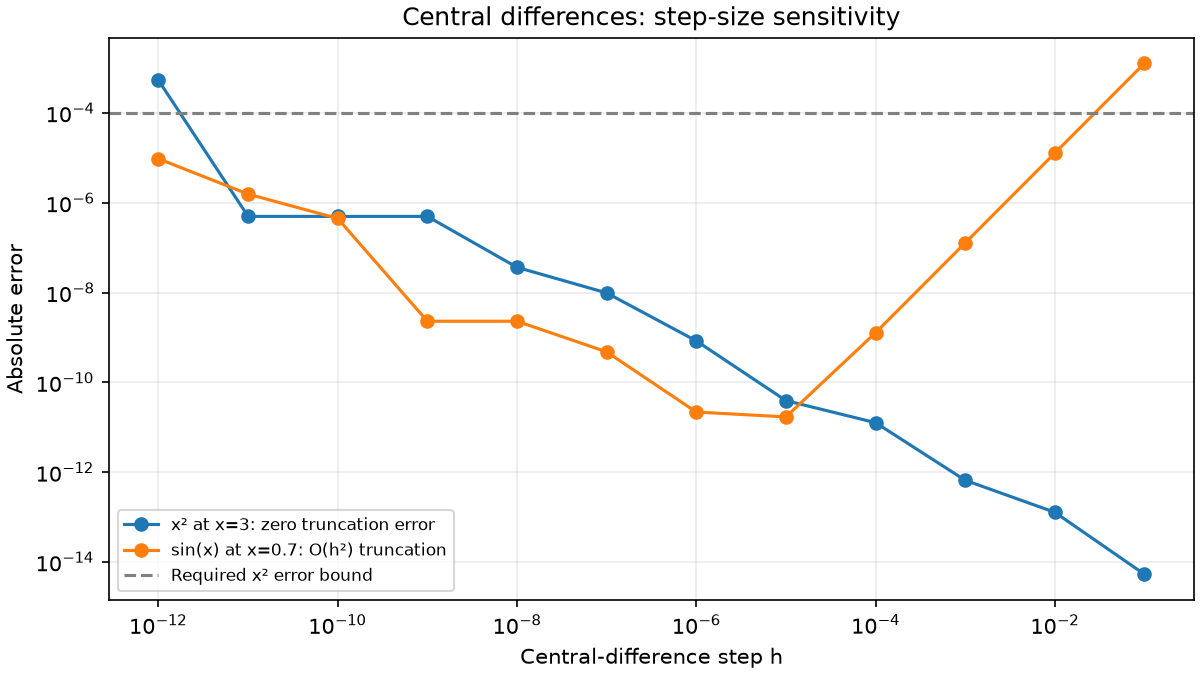

In [4]:
from scripts.experiment_evidence import derivative_step_study
rows = derivative_step_study()
display_table(["h", "x² 수치미분", "x² 절대오차", "sin 절대오차"], [
    [f'{r["h"]:.0e}', f'{r["square_derivative"]:.10f}',
     f'{r["square_error"]:.3e}', f'{r["sine_error"]:.3e}'] for r in rows])
for i in (0, 1):
    assert 95 < rows[i]["sine_error"]/rows[i+1]["sine_error"] < 105
display(Image(filename=str(ROOT / "outputs/derivative_step_study.png")))

## 4. Optimizer hyperparameters and fixed initial conditions

모든 실험의 초기점은 [5,5], 재현 시드는 42다.
Momentum은 v=beta*v+gradient 관례를 사용한다.
Adam의 beta1=0.9, beta2=0.999, eps=1e-8,
Newton의 damping=1과 Hessian=diag(2,20)을 명시한다.
확률적인 업데이트는 없지만 시드를 일관되게 고정한다.

In [5]:
# Initial point=[5,5], seed=42, steps=100, lr=0.1 for mandatory GD.
from src.optimizer import VanillaGD, optimize, quadratic_gradient
np.random.seed(42)
initial, steps, lr = np.array([5., 5.]), 100, .1
gd = optimize(quadratic_gradient, initial, VanillaGD(lr), steps)
assert np.linalg.norm(gd[-1]) <= .1
# Ellipse comparisons use the SAME initial point, lr=0.09 or 0.01,
# respectively 200 or 300 steps; beta=0.9 for Momentum.
display_table(["실험", "함수", "방법", "초기점", "seed", "steps", "lr", "추가 파라미터"], [
    [r["experiment"], r["function"], r["optimizer"], r["initial"],
     r["seed"], r["steps"], r["lr"],
     {k: r[k] for k in ["beta", "beta1", "beta2", "eps", "damping", "hessian"]
      if r.get(k) is not None}]
    for r in metrics["optimizer_experiments"]])
print("GD final point:", gd[-1], "radius:", np.linalg.norm(gd[-1]))

| 실험 | 함수 | 방법 | 초기점 | seed | steps | lr | 추가 파라미터 |
|---|---|---|---|---|---|---|---|
| circle | x²+1y² | VanillaGD | [5, 5] | 42 | 100 | 0.1 | {} |
| circle | x²+1y² | Momentum | [5, 5] | 42 | 100 | 0.1 | {'beta': 0.9} |
| ellipse | x²+10y² | VanillaGD | [5, 5] | 42 | 200 | 0.09 | {} |
| ellipse | x²+10y² | Momentum | [5, 5] | 42 | 200 | 0.09 | {'beta': 0.9} |
| bonus_optimizers | x²+10y² | VanillaGD | [5, 5] | 42 | 300 | 0.01 | {} |
| bonus_optimizers | x²+10y² | Momentum | [5, 5] | 42 | 300 | 0.01 | {'beta': 0.9} |
| bonus_optimizers | x²+10y² | Adam | [5, 5] | 42 | 300 | 0.1 | {'beta1': 0.9, 'beta2': 0.999, 'eps': 1e-08} |
| newton | x²+10y² | Newton | [5, 5] | 42 | 3 | None | {'damping': 1.0, 'hessian': 'diag(2,20)'} |

GD final point: [0.000000001 0.000000001] radius: 1.4404019523870759e-09


## 5. Divergence verification for lr >= 0.5

**lr≥0.5 구간에서 lr=1.1, 1.2, 1.5를 선택하여 발산을 검증한다.**
초기점=[5,5], seed=42, steps=30, 함수 f=x²+y², gradient=(2x,2y).

$$\theta_t=(1-2lr)^t\theta_0,\qquad
\|\theta_t\|=|1-2lr|^t\|\theta_0\|.$$

세 선택값의 증폭률은 각각 1.2, 1.4, 2.0이므로 모두 발산한다.
단순히 최종값이 크다는 관찰에 더해, 모든 단계의 거리 증가와
해석식 일치를 검증하여 발산 근거를 보강한다.
lr=0.5,0.75,1.0의 경계 실험도 아래 표에 함께 공개한다.
이 함수에서 "모든 lr≥0.5가 발산"은 성립하지 않는다.

| lr | 갱신 계수 | 관측/해석 결과 | 거리 배율 (30회) | 매 단계 증가 |
|---|---|---|---|---|
| 0.5 | 0.00 | convergent | 0 | False |
| 0.75 | -0.50 | convergent | 9.31323e-10 | False |
| 1.0 | -1.00 | neutral oscillation | 1 | False |
| 1.1 | -1.20 | divergent | 237.376 | True |
| 1.2 | -1.40 | divergent | 24201.4 | True |
| 1.5 | -2.00 | divergent | 1.07374e+09 | True |

PASS: lr>=0.5 범위에서 선택한 1.1, 1.2, 1.5의 발산 확인


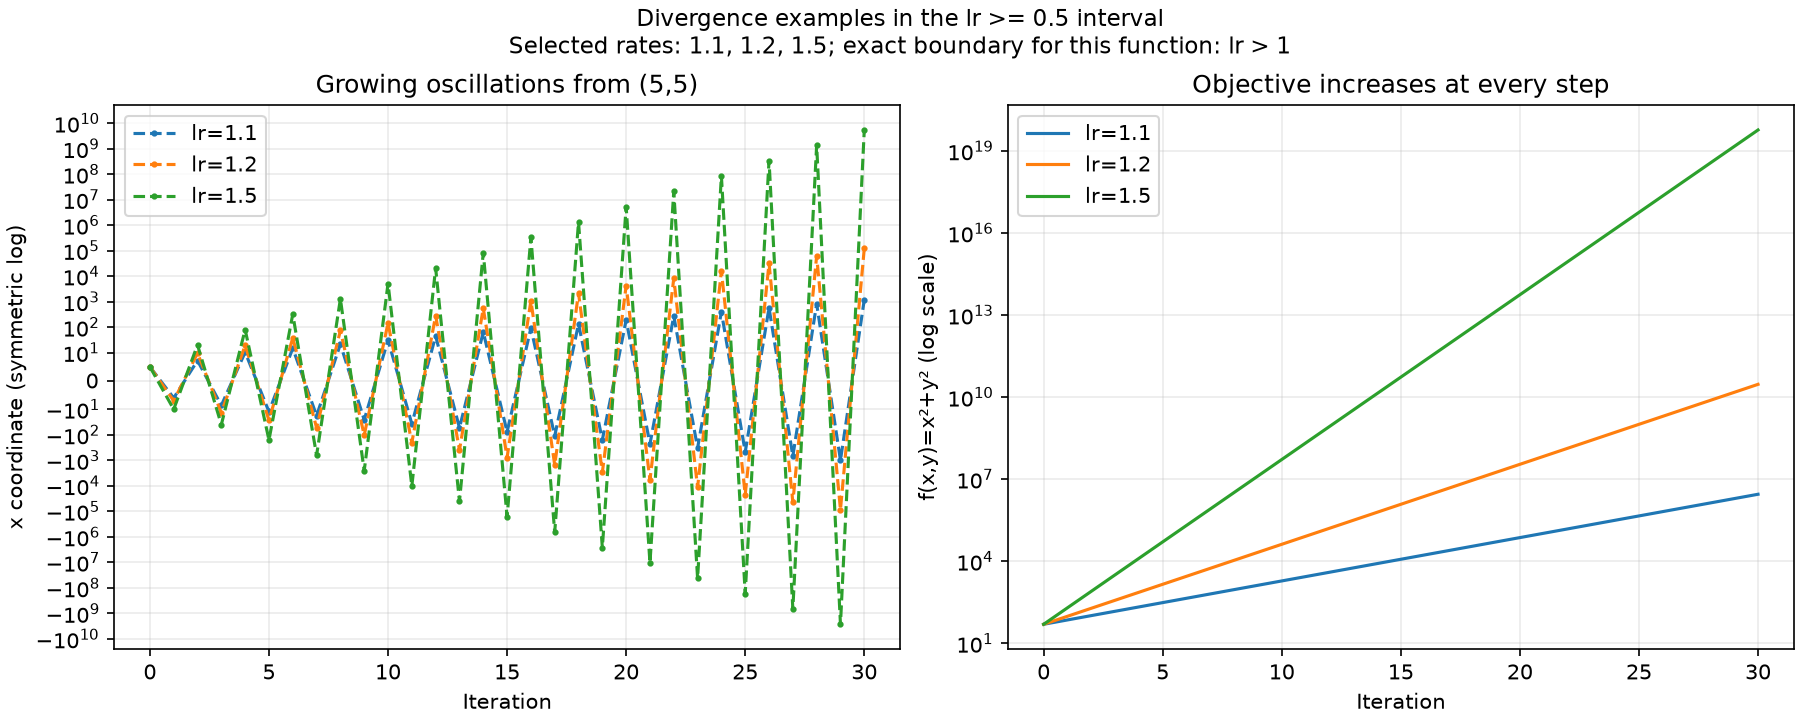

In [6]:
# Initial point=[5,5], seed=42, steps=30; tested lr=[.5,.75,1,1.1,1.2,1.5].
from scripts.experiment_evidence import divergence_study
evidence, paths = divergence_study(steps=30)
selected = evidence["demonstrated_divergent_rates"]
display_table(["lr", "갱신 계수", "관측/해석 결과", "거리 배율 (30회)", "매 단계 증가"], [
    [r["lr"], f'{r["update_factor"]:.2f}', r["expected_behavior"],
     f'{r["radius_growth_factor"]:.6g}', r["every_step_grows"]]
    for r in evidence["runs"]])
for row in evidence["runs"]:
    if row["lr"] in selected:
        assert row["lr"] >= .5
        assert abs(row["update_factor"]) > 1
        assert row["closed_form_verified"] and row["every_step_grows"]
        assert row["radius_growth_factor"] > 100
print("PASS: lr>=0.5 범위에서 선택한 1.1, 1.2, 1.5의 발산 확인")
display(Image(filename=str(ROOT / evidence["figure"])))